In [2]:
import sys
from pathlib import Path


# =========================
# 1. 项目路径
# =========================

PROJECT_ROOT = Path(
    r"D:\Codex\medical-evidence-agent\python_proj\search_api"
)

# 确保导入的是项目自己的 app，而不是之前误装的 PyPI app
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# =========================
# 2. 导入阶段 8 的模块
# =========================

from app.medical_models import (
    EvidenceSpan,
    EvidenceValue,
    StructuredEvidence,
)

from app.knowledge_graph import (
    build_evidence_graph,
    write_graph_json,
)


# =========================
# 3. 构造一条可追溯的演示证据
# =========================

def missing_value():
    return EvidenceValue(
        value=None,
        status="not_reported_in_abstract",
        evidence_ids=[],
    )


pmid = "123456"
source_url = "https://pubmed.ncbi.nlm.nih.gov/123456/"
title = "Immunotherapy in lung cancer"


record = StructuredEvidence(
    pmid=pmid,
    source_url=source_url,
    title=title,
    title_evidence_ids=["title-1"],

    research_object=missing_value(),

    disease=EvidenceValue(
        value="lung cancer",
        status="reported",
        evidence_ids=["disease-1"],
    ),

    method=EvidenceValue(
        value="cohort study",
        status="reported",
        evidence_ids=["method-1"],
    ),

    dataset=EvidenceValue(
        value="public clinical dataset",
        status="reported",
        evidence_ids=["dataset-1"],
    ),

    main_findings=missing_value(),
    limitations=missing_value(),

    evidence_spans=[
        EvidenceSpan(
            evidence_id="title-1",
            pmid=pmid,
            source_section="title",
            exact_text=title,
            source_url=source_url,
        ),
        EvidenceSpan(
            evidence_id="disease-1",
            pmid=pmid,
            source_section="abstract",
            exact_text="lung cancer",
            source_url=source_url,
        ),
        EvidenceSpan(
            evidence_id="method-1",
            pmid=pmid,
            source_section="abstract",
            exact_text="cohort study",
            source_url=source_url,
        ),
        EvidenceSpan(
            evidence_id="dataset-1",
            pmid=pmid,
            source_section="abstract",
            exact_text="public clinical dataset",
            source_url=source_url,
        ),
    ],
)


# =========================
# 4. 生成知识图谱
# =========================

graph = build_evidence_graph([record])

print("论文节点数量：", graph.paper_count)
print("关系数量：", graph.relation_count)


# =========================
# 5. 保存 JSON
# =========================

GRAPH_JSON = (
    PROJECT_ROOT
    / "artifacts"
    / "evidence_graph_demo.json"
)

write_graph_json(
    graph,
    GRAPH_JSON,
)

print("图谱 JSON 已生成：")
print(GRAPH_JSON)
print("文件是否存在：", GRAPH_JSON.exists())

论文节点数量： 1
关系数量： 3
图谱 JSON 已生成：
D:\Codex\medical-evidence-agent\python_proj\search_api\artifacts\evidence_graph_demo.json
文件是否存在： True


读取到 4 个节点
读取到 3 条关系


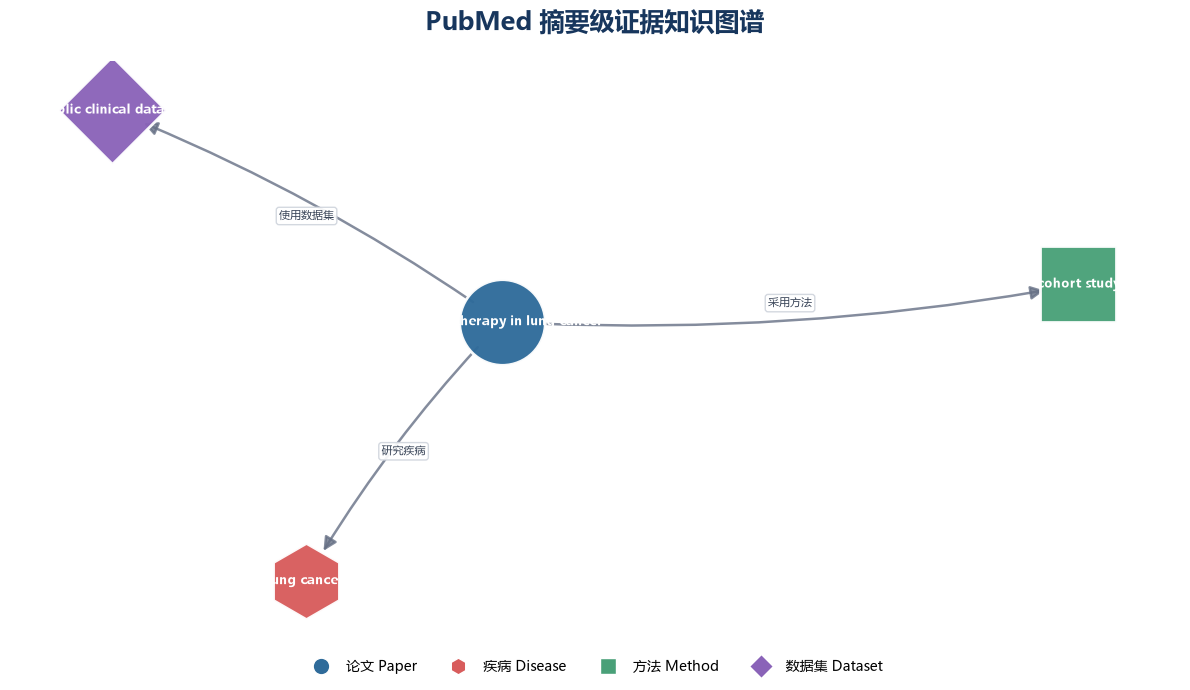

高清图片已保存到：
D:\Codex\medical-evidence-agent\python_proj\search_api\artifacts\evidence_graph_visualization.png


In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D


# =========================
# 1. 文件位置
# =========================

PROJECT_ROOT = Path(
    r"D:\Codex\medical-evidence-agent\python_proj\search_api"
)

GRAPH_JSON = (
    PROJECT_ROOT
    / "artifacts"
    / "evidence_graph_demo.json"
)

OUTPUT_PNG = (
    PROJECT_ROOT
    / "artifacts"
    / "evidence_graph_visualization.png"
)


if not GRAPH_JSON.exists():
    raise FileNotFoundError(
        f"没有找到知识图谱文件：\n{GRAPH_JSON}\n"
        "请先运行前面的知识图谱生成代码。"
    )


# =========================
# 2. 读取知识图谱 JSON
# =========================

with open(GRAPH_JSON, "r", encoding="utf-8") as file:
    graph_data = json.load(file)

nodes = graph_data.get("nodes", [])
edges = graph_data.get("edges", [])

print(f"读取到 {len(nodes)} 个节点")
print(f"读取到 {len(edges)} 条关系")


# =========================
# 3. 创建 NetworkX 图
# =========================

# 使用 DiGraph，表示有方向的关系
G = nx.DiGraph()

for node in nodes:
    G.add_node(
        node["id"],
        node_type=node["type"],
        label=node["label"],
        pmid=node.get("pmid"),
        source_url=node.get("source_url"),
    )


# 同一对节点可能存在多个证据片段，
# 可视化时将关系合并，避免重复线条重叠
for edge in edges:
    source = edge["source"]
    target = edge["target"]
    relation = edge["relation"]

    if G.has_edge(source, target):
        relations = G[source][target]["relations"]

        if relation not in relations:
            relations.append(relation)

        G[source][target]["evidence"].append(
            {
                "pmid": edge["pmid"],
                "evidence_id": edge["evidence_id"],
                "source_section": edge["source_section"],
                "evidence_text": edge["evidence_text"],
                "source_url": edge["source_url"],
            }
        )

    else:
        G.add_edge(
            source,
            target,
            relations=[relation],
            evidence=[
                {
                    "pmid": edge["pmid"],
                    "evidence_id": edge["evidence_id"],
                    "source_section": edge["source_section"],
                    "evidence_text": edge["evidence_text"],
                    "source_url": edge["source_url"],
                }
            ],
        )


# =========================
# 4. 绘图设置
# =========================

plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False


node_styles = {
    "Paper": {
        "color": "#2F6B9A",
        "shape": "o",
        "size": 3800,
        "legend": "论文 Paper",
    },
    "Disease": {
        "color": "#D85C5C",
        "shape": "h",
        "size": 3000,
        "legend": "疾病 Disease",
    },
    "Method": {
        "color": "#49A078",
        "shape": "s",
        "size": 3000,
        "legend": "方法 Method",
    },
    "Dataset": {
        "color": "#8A63B8",
        "shape": "D",
        "size": 3000,
        "legend": "数据集 Dataset",
    },
}


node_count = max(len(G.nodes), 1)

figure_width = max(12, min(20, 8 + node_count * 0.7))
figure_height = max(7, min(13, 5 + node_count * 0.4))

fig, ax = plt.subplots(
    figsize=(figure_width, figure_height),
    facecolor="white",
)


# 固定随机种子，保证每次布局基本一致
position = nx.spring_layout(
    G,
    seed=42,
    k=max(0.9, 2.2 / (node_count ** 0.5)),
    iterations=300,
)


# =========================
# 5. 分类型绘制节点
# =========================

for node_type, style in node_styles.items():

    selected_nodes = [
        node_id
        for node_id, attributes in G.nodes(data=True)
        if attributes.get("node_type") == node_type
    ]

    if not selected_nodes:
        continue

    nx.draw_networkx_nodes(
        G,
        position,
        nodelist=selected_nodes,
        node_color=style["color"],
        node_shape=style["shape"],
        node_size=style["size"],
        edgecolors="white",
        linewidths=2,
        alpha=0.96,
        ax=ax,
    )


# =========================
# 6. 绘制关系箭头
# =========================

nx.draw_networkx_edges(
    G,
    position,
    edge_color="#667085",
    width=1.8,
    alpha=0.8,
    arrows=True,
    arrowsize=20,
    arrowstyle="-|>",
    min_source_margin=25,
    min_target_margin=25,
    connectionstyle="arc3,rad=0.06",
    ax=ax,
)


# =========================
# 7. 节点标签
# =========================

def shorten_label(text, max_length=30):
    """防止论文标题太长导致图片拥挤。"""

    text = str(text)

    if len(text) <= max_length:
        return text

    return text[:max_length] + "..."


node_labels = {
    node_id: shorten_label(attributes.get("label", node_id))
    for node_id, attributes in G.nodes(data=True)
}

nx.draw_networkx_labels(
    G,
    position,
    labels=node_labels,
    font_size=9,
    font_color="white",
    font_weight="bold",
    font_family="Microsoft YaHei",
    ax=ax,
)


# =========================
# 8. 关系标签
# =========================

relation_names = {
    "studies_disease": "研究疾病",
    "uses_method": "采用方法",
    "uses_dataset": "使用数据集",
}

edge_labels = {}

for source, target, attributes in G.edges(data=True):
    relations = attributes.get("relations", [])

    edge_labels[(source, target)] = "\n".join(
        relation_names.get(relation, relation)
        for relation in relations
    )


nx.draw_networkx_edge_labels(
    G,
    position,
    edge_labels=edge_labels,
    font_size=8,
    font_color="#344054",
    font_family="Microsoft YaHei",
    rotate=False,
    bbox={
        "boxstyle": "round,pad=0.25",
        "facecolor": "white",
        "edgecolor": "#D0D5DD",
        "alpha": 0.92,
    },
    ax=ax,
)


# =========================
# 9. 图例
# =========================

legend_items = []

for node_type, style in node_styles.items():

    if any(
        attributes.get("node_type") == node_type
        for _, attributes in G.nodes(data=True)
    ):
        legend_items.append(
            Line2D(
                [0],
                [0],
                marker=style["shape"],
                color="none",
                markerfacecolor=style["color"],
                markeredgecolor="white",
                markersize=12,
                label=style["legend"],
            )
        )


ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=max(1, len(legend_items)),
    frameon=False,
    fontsize=10,
)


# =========================
# 10. 标题与保存
# =========================

ax.set_title(
    "PubMed 摘要级证据知识图谱",
    fontsize=18,
    fontweight="bold",
    color="#17365D",
    pad=22,
)

ax.axis("off")

plt.tight_layout()

OUTPUT_PNG.parent.mkdir(
    parents=True,
    exist_ok=True,
)

plt.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"高清图片已保存到：\n{OUTPUT_PNG}")